In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sn
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV)
from sklearn.ensemble import RandomForestClassifier
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             recall_score, precision_score, roc_auc_score)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


SEED = 42 
np.random.seed(SEED)

In [3]:
df = pd.read_csv("realistic_credit_scoring_dataset-1.csv")


X = df.drop(columns = "Loan_Status")
y = df["Loan_Status"].map({"Default": 1, "Paid": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)


In [4]:
bayes = GaussianNB()
bayes.fit(X_train,y_train)

y_pred = bayes.predict(X_test)
y_pred_proba = bayes.predict_proba(X_test)[:, 1]

acc_bayes = accuracy_score(y_test, y_pred)
prec_bayes = precision_score(y_test, y_pred)
rec_bayes = recall_score(y_test, y_pred)
f1_bayes = f1_score(y_test, y_pred)
roc_bayes = roc_auc_score(y_test, y_pred_proba)


print( 
    "   Naive_Bayes metrics   \n"
    f" accuracy:  {acc_bayes: .3f} \n"
    f" precision: {prec_bayes: .3f} \n"
    f" recall:    {rec_bayes: .3f} \n"
    f" f1-score:  {f1_bayes: .3f}  \n"
    f" roc_auc:   {roc_bayes: .3f} \n"
)

   Naive_Bayes metrics   
 accuracy:   0.955 
 precision:  0.920 
 recall:     0.893 
 f1-score:   0.906  
 roc_auc:    0.992 



   decision tree metrics   
 accuracy:   0.999 
 precision:  0.996 
 recall:     0.999 
 f1-score:   0.997  
 roc_auc:    0.999 



[Text(0.3076923076923077, 0.9444444444444444, 'x[12] <= 0.45\ngini = 0.372\nsamples = 12000\nvalue = [9038, 2962]'),
 Text(0.23076923076923078, 0.8333333333333334, 'x[12] <= 0.449\ngini = 0.003\nsamples = 9050\nvalue = [9038, 12]'),
 Text(0.2692307692307693, 0.8888888888888888, 'True  '),
 Text(0.15384615384615385, 0.7222222222222222, 'gini = 0.0\nsamples = 9023\nvalue = [9023, 0]'),
 Text(0.3076923076923077, 0.7222222222222222, 'x[0] <= 28.5\ngini = 0.494\nsamples = 27\nvalue = [15, 12]'),
 Text(0.15384615384615385, 0.6111111111111112, 'x[8] <= 8.5\ngini = 0.32\nsamples = 5\nvalue = [1, 4]'),
 Text(0.07692307692307693, 0.5, 'gini = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.23076923076923078, 0.5, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.46153846153846156, 0.6111111111111112, 'x[5] <= 1.5\ngini = 0.463\nsamples = 22\nvalue = [14, 8]'),
 Text(0.38461538461538464, 0.5, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.5384615384615384, 0.5, 'x[5] <= 6.5\ngini = 0.42\nsampl

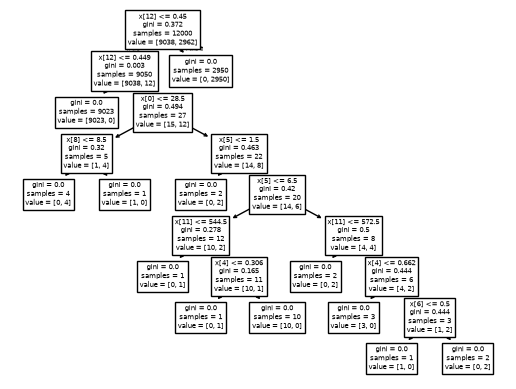

In [6]:
tree_model = tree.DecisionTreeClassifier()
tree_model.fit(X_train, y_train)

y_pred = tree_model.predict(X_test)
y_pred_proba = tree_model.predict_proba(X_test)[:, 1]

acc_tree = accuracy_score(y_test, y_pred)
prec_tree = precision_score(y_test, y_pred)
rec_tree = recall_score(y_test, y_pred)
f1_tree = f1_score(y_test, y_pred)
roc_tree = roc_auc_score(y_test, y_pred_proba)


print( 
    "   decision tree metrics   \n"
    f" accuracy:  {acc_tree: .3f} \n"
    f" precision: {prec_tree: .3f} \n"
    f" recall:    {rec_tree: .3f} \n"
    f" f1-score:  {f1_tree: .3f}  \n"
    f" roc_auc:   {roc_tree: .3f} \n"
)

tree.plot_tree(tree_model)

In [8]:
forest_model = RandomForestClassifier()
forest_model.fit(X_train, y_train)

y_pred = forest_model.predict(X_test)
y_pred_proba = forest_model.predict_proba(X_test)[:, 1]

acc_forest = accuracy_score(y_test, y_pred)
prec_forest = precision_score(y_test, y_pred)
rec_forest = recall_score(y_test, y_pred)
f1_forest = f1_score(y_test, y_pred)
roc_forest = roc_auc_score(y_test, y_pred_proba)


print( 
    "   random forest metrics   \n"
    f" accuracy:  {acc_forest:.3f} \n"
    f" precision: {prec_forest:.3f} \n"
    f" recall:    {rec_forest:.3f} \n"
    f" f1-score:  {f1_forest:.3f}  \n"
    f" roc_auc:   {roc_forest:.3f} \n"
)

   random forest metrics   
 accuracy:  0.999 
 precision: 0.999 
 recall:    0.997 
 f1-score:  0.998  
 roc_auc:   1.000 

